# CS4100 — Data Cleaning & EDA for Popularity-Bias Recommenders
**Amazon Reviews 2023** · Popularity baseline · Item-CF · Matrix Factorization · Neural model

Run this notebook once per category (`All_Beauty` / `Beauty_and_Personal_Care`, `Amazon_Fashion`, `Clothing_Shoes_and_Jewelry`) by changing `CATEGORY`, then use Section 4 to compare categories side by side.

**Which fields actually matter**

| Need | Fields | Used by |
|---|---|---|
| Core interaction matrix | `user_id`, `parent_asin`, `rating`, `timestamp` | all 4 models |
| Relevance definition / filtering | `verified_purchase`, `rating` | evaluation |
| Popularity measurement | counts from reviews (+ `rating_number` from meta as a cross-check) | bias metrics |
| Context / side features | `main_category`, `store`, `price`, `categories`, `details` (brand) | EDA, optional neural features |
| Text | review `title`/`text`, item `title`/`features`/`description` | only if the neural model uses content |

Use **`parent_asin`** as the item ID everywhere: variants (size/colour) of one product share it, and metadata is keyed on it. `asin` would split one product into many "items" and fake a longer tail.

## 0. Setup & loading

In [5]:
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

DATA_DIR = Path(r"D:\CS4100\group project\popularity-bias-recsys\data\interim")
CATEGORY = "Beauty_and_Personal_Care"

REVIEW_PATH = DATA_DIR / f"{CATEGORY}_full.parquet" 
META_PATH   = DATA_DIR / f"{CATEGORY}_meta.parquet"

REVIEW_COLS = ["user_id", "parent_asin", "rating", "timestamp", "verified_purchase"]
META_COLS   = ["parent_asin", "main_category", "store", "price",
               "average_rating", "rating_number", "details", "categories"]

print("DATA_DIR:", DATA_DIR)
print("REVIEW_PATH exists:", REVIEW_PATH.exists())
print("META_PATH exists:  ", META_PATH.exists())

DATA_DIR: D:\CS4100\group project\popularity-bias-recsys\data\interim
REVIEW_PATH exists: True
META_PATH exists:   True


In [14]:
from pathlib import Path

DATA_DIR = Path(r"D:\CS4100\group project\popularity-bias-recsys\data\interim")

print("DATA_DIR:", DATA_DIR)
print("exists:", DATA_DIR.exists())
print("files:", [p.name for p in DATA_DIR.glob("*.parquet")])

DATA_DIR: D:\CS4100\group project\popularity-bias-recsys\data\interim
exists: True
files: ['Beauty_and_Personal_Care_full.parquet', 'Beauty_and_Personal_Care_meta.parquet']


In [8]:
import pyarrow as pa
import pyarrow.parquet as pq

def read_parquet_light(path, columns, batch_size=500_000):
    pf = pq.ParquetFile(path)
    chunks = []
    total = 0
    for batch in pf.iter_batches(batch_size=batch_size, columns=columns):
        df = batch.to_pandas()
        for col in df.columns:
            if df[col].dtype == "object":
                df[col] = df[col].astype("category")
        chunks.append(df)
        total += len(df)
        print(f"  read {total:,} rows", end="\r")
    print()
    return pd.concat(chunks, ignore_index=True)

reviews = read_parquet_light(REVIEW_PATH, REVIEW_COLS)
meta    = pd.read_parquet(META_PATH, columns=META_COLS)

print("reviews:", reviews.shape, "| meta:", meta.shape)
print(reviews.dtypes)
reviews.head()

  read 23,911,390 rows
reviews: (23911390, 5) | meta: (1028914, 8)
user_id                  str
parent_asin              str
rating               float64
timestamp              int64
verified_purchase    boolean
dtype: object


,user_id,parent_asin,rating,timestamp,verified_purchase
0,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B00Z03RC80,1.0,1616743454733,True
1,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B085PRT2MP,1.0,1614915977684,True
2,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B08G81QQ9L,5.0,1612052493701,True
3,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B07YYG76X1,1.0,1609700981786,True
4,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B07X4FKLNK,3.0,1581313195358,True


## 1. Data cleaning

### 1.1 Types, ranges and missing values
**Why:** `timestamp` is Unix time in *milliseconds*; you need real datetimes for the temporal split. Ratings outside 1–5 or missing IDs would silently corrupt the user–item matrix.

In [10]:
reviews["timestamp"] = pd.to_datetime(reviews["timestamp"], unit="ms")
reviews["rating"] = pd.to_numeric(reviews["rating"], errors="coerce")

print("Date range:", reviews["timestamp"].min(), "->", reviews["timestamp"].max())
print("Ratings outside 1-5:", (~reviews["rating"].between(1, 5)).sum())
print("Missing values:\n", reviews.isna().sum())
# print("Empty review text:", (reviews["text"].fillna("").str.strip() == "").sum())

# IDs and rating are mandatory for every model
reviews = reviews.dropna(subset=["user_id", "parent_asin", "rating", "timestamp"])

Date range: 2000-04-01 08:10:29 -> 2023-09-13 16:30:23.621000
Ratings outside 1-5: 0
Missing values:
 user_id              0
parent_asin          0
rating               0
timestamp            0
verified_purchase    0
dtype: int64


### 1.2 Duplicate user–item interactions
**Why:** Item-CF and MF assume one cell per (user, item). The same user can review several variants of one parent product, or post exact duplicates. Duplicates inflate an item's popularity count and can leak into the test set. Keep the **latest** review per pair.

In [11]:
n0 = len(reviews)

# only calculate duplications 
n_exact_dup = reviews.duplicated().sum()

# only calculate duplications 
n_pair_dup = reviews.duplicated(["user_id", "parent_asin"], keep=False).sum()

print(f"rows: {n0:,}")
print(f"exact duplicate rows: {n_exact_dup:,} ({n_exact_dup/n0:.4%})")
print(f"rows in repeated (user, item) pairs: {n_pair_dup:,} ({n_pair_dup/n0:.4%})")

rows: 23,911,390
exact duplicate rows: 242,535 (1.0143%)
rows in repeated (user, item) pairs: 594,187 (2.4850%)


In [13]:
print("DATA_DIR   =", repr(DATA_DIR))
print("CATEGORY   =", repr(CATEGORY))
print("REVIEW_PATH=", repr(REVIEW_PATH))

DATA_DIR   = WindowsPath('D:/CS4100/group project/popularity-bias-recsys/Beauty and Personal Care/data/interim')
CATEGORY   = 'Beauty_and_Personal_Care'
REVIEW_PATH= WindowsPath('D:/CS4100/group project/popularity-bias-recsys/data/interim/Beauty_and_Personal_Care_full.parquet')


In [15]:
import duckdb
from pathlib import Path

src = str(REVIEW_PATH).replace("\\", "/")
dst = str(DATA_DIR / f"{CATEGORY}_dedup.parquet").replace("\\", "/")

con = duckdb.connect()
con.execute(f"""
    COPY (
        SELECT user_id, parent_asin, rating, timestamp, verified_purchase
        FROM (
            SELECT *,
                   ROW_NUMBER() OVER (
                       PARTITION BY user_id, parent_asin
                       ORDER BY timestamp DESC
                   ) AS rn
            FROM read_parquet('{src}')
        )
        WHERE rn = 1
    ) TO '{dst}' (FORMAT PARQUET)
""")
con.close()

print("saved to", dst)

saved to D:/CS4100/group project/popularity-bias-recsys/data/interim/Beauty_and_Personal_Care_dedup.parquet


### 1.3 Verified purchases
**Why:** Your proposal defines relevance as "did the user actually buy it". Unverified reviews may be gifts, free samples or incentivised reviews. Check how much data you'd lose before deciding to filter, and whether unverified reviews rate differently.

In [16]:
print(reviews["verified_purchase"].value_counts(normalize=True))
print(reviews.groupby("verified_purchase")["rating"].agg(["mean", "count"]))

ONLY_VERIFIED = True   # decide as a team and keep it the same across categories
if ONLY_VERIFIED:
    reviews = reviews[reviews["verified_purchase"] == True].copy()
print("Rows kept:", len(reviews))

verified_purchase
True     0.911088
False    0.088912
Name: proportion, dtype: Float64
                       mean     count
verified_purchase                    
False              4.117337   2126021
True               4.111324  21785369
Rows kept: 21785369


In [ ]:
# check the how much item lost from head 
# before filte
pre = reviews.copy()
pre_counts = pre["parent_asin"].value_counts()
pre_head = set(pre_counts.cumsum()[pre_counts.cumsum() / pre_counts.sum() <= 0.2].index)

# after filte
post_counts = reviews["parent_asin"].value_counts()
post_head = set(post_counts.cumsum()[post_counts.cumsum() / post_counts.sum() <= 0.2].index)

print("head items before:", len(pre_head))
print("head items after: ", len(post_head))
print("items lost from head:", len(pre_head - post_head))
print("items lost overall:", pre["parent_asin"].nunique() - reviews["parent_asin"].nunique())

head items before: 1383
head items after:  1383
items lost from head: 0
items lost overall: 0


### 1.4 Metadata cleaning and join coverage
**Why:** `price` often arrives as a string or `"None"`; `store` and `main_category` have gaps; `details` is a dict you can mine for brand. Also check what share of reviewed items actually *have* metadata: any side-feature analysis only covers those.

In [ ]:
import numpy as np

# drop duplication for meta
meta = meta.drop_duplicates("parent_asin")

# flattened fields cleaning 
meta["price"] = pd.to_numeric(meta["price"], errors="coerce")
meta["store"] = meta["store"].replace("", np.nan)

# Optional: Use regular expressions to directly extract the brand from the JSON string without parsing the entire dict
meta["brand"] = meta["details"].str.extract(r'"Brand"\s*:\s*"([^"]*)"', expand=False)
meta["brand"] = meta["brand"].fillna(
    meta["details"].str.extract(r'"brand"\s*:\s*"([^"]*)"', expand=False)
)

# Optional: Estimate the number of categories using the number of commas without parsing the list
meta["n_categories"] = meta["categories"].fillna("").str.count(",") + 1
meta.loc[meta["categories"].isna(), "n_categories"] = 0

# check lost 
print("Meta missing share:\n",
      meta[["main_category", "price", "store", "brand"]].isna().mean())

# Coverage: How many of the items that have been commented on are recorded in meta
reviewed_items = reviews["parent_asin"].unique()
coverage = meta["parent_asin"].isin(reviewed_items).mean()
print(f"Reviewed items with metadata: {coverage:.2%}")

Meta missing share:
 main_category    0.100004
price            0.630098
store            0.049288
brand            0.304385
dtype: float64
Reviewed items with metadata: 94.01%


### 1.5 Explicit ratings → implicit feedback
**Why:** The `implicit` library, the popularity baseline and top-K ranking metrics all work on implicit signals (did the user interact / like it?). Pick one definition and keep it fixed across models:
- **Option A:** every (verified) review is a positive interaction. Simple, and the most common choice in the literature.
- **Option B:** only ratings ≥ 4 are positives. Closer to "the user liked it", but drops data.

In [21]:
POSITIVE_THRESHOLD = None   # None = Option A
if POSITIVE_THRESHOLD:
    interactions = reviews[reviews["rating"] >= POSITIVE_THRESHOLD].copy()
else:
    interactions = reviews.copy()
interactions = interactions[["user_id", "parent_asin", "rating", "timestamp"]]
print("Interactions:", len(interactions))
print(interactions["timestamp"].dtype)

Interactions: 21785369
datetime64[us]


In [22]:
def summarize(df, label=""):
    n_u = df["user_id"].nunique()
    n_i = df["parent_asin"].nunique()
    n = len(df)
    return pd.Series({
        "interactions": n,
        "users": n_u,
        "items": n_i,
        "density": n / (n_u * n_i) if n_u and n_i else np.nan,
        "avg_per_user": n / n_u if n_u else np.nan,
        "avg_per_item": n / n_i if n_i else np.nan,
    }, name=label)

## 2. Exploratory data analysis

### 2.1 Rating distribution
**Why:** Amazon ratings are typically J-shaped (mostly 5s). If almost everything is 5★, explicit ratings carry little signal, which supports treating the data as implicit (1.5).

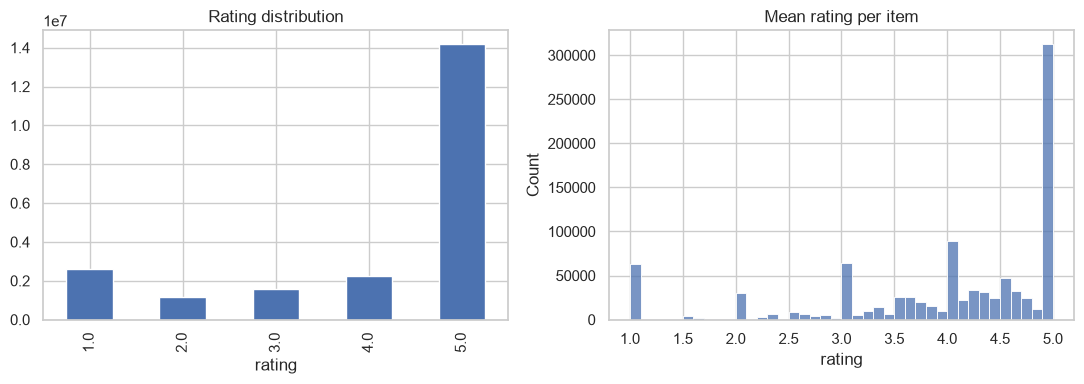

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
reviews["rating"].value_counts().sort_index().plot.bar(ax=axes[0], title="Rating distribution")
sns.histplot(reviews.groupby("parent_asin")["rating"].mean(), bins=40, ax=axes[1])
axes[1].set_title("Mean rating per item")
plt.tight_layout(); plt.show()

### 2.2 The long tail: item popularity, Lorenz curve, Gini
**Why:** This is the core of your project. You need a baseline measure of how concentrated the *data* is, so you can later say whether each model's recommendations are *more* concentrated (amplification) or less.

- **Gini coefficient:** 0 = every item equally popular, 1 = one item gets everything.
- **Short head / long tail:** following Abdollahpouri et al., the *head* is the most popular items that together account for 20% of interactions. These labels are reused later for metrics like APLT (share of long-tail items in recommendations).

Gini=0.859 | head items: 1,383 (0.14% of items -> 20% of interactions)


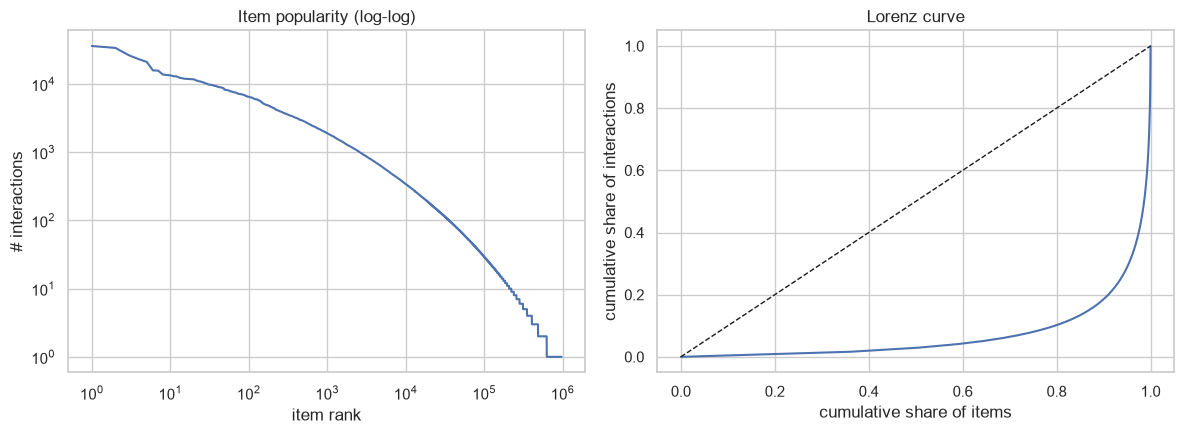

In [24]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n, cum = len(x), np.cumsum(x)
    return (n + 1 - 2 * (cum / cum[-1]).sum()) / n

def head_tail(df, head_share=0.20):
    counts = df["parent_asin"].value_counts()            # sorted descending
    cum = counts.cumsum() / counts.sum()
    head = set(cum[cum <= head_share].index) or {counts.index[0]}
    return counts, head

def lorenz(counts):
    x = np.sort(counts.values)
    y = np.insert(np.cumsum(x) / x.sum(), 0, 0)
    return np.linspace(0, 1, len(y)), y

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

counts, head = head_tail(interactions)
print(f"Gini={gini(counts):.3f} | head items: {len(head):,} "
      f"({len(head)/len(counts):.2%} of items -> 20% of interactions)")

axes[0].loglog(np.arange(1, len(counts) + 1), counts.values)
axes[1].plot(*lorenz(counts))
axes[0].set(title="Item popularity (log-log)", xlabel="item rank", ylabel="# interactions")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set(title="Lorenz curve", xlabel="cumulative share of items",
            ylabel="cumulative share of interactions")
plt.tight_layout(); plt.show()

item_counts, HEAD_ITEMS = head_tail(interactions)

### 2.3 User activity & cold start
**Why:** If most users have 1–2 interactions, leave-one-out evaluation leaves them with almost no training history. This tells you how much k-core you need and how many users you'll actually be able to evaluate.

Users with exactly 1 interaction: 62.31%
count    1.081496e+07
mean     2.014373e+00
std      2.612086e+00
min      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
90%      4.000000e+00
99%      1.200000e+01
max      4.240000e+02
Name: count, dtype: float64


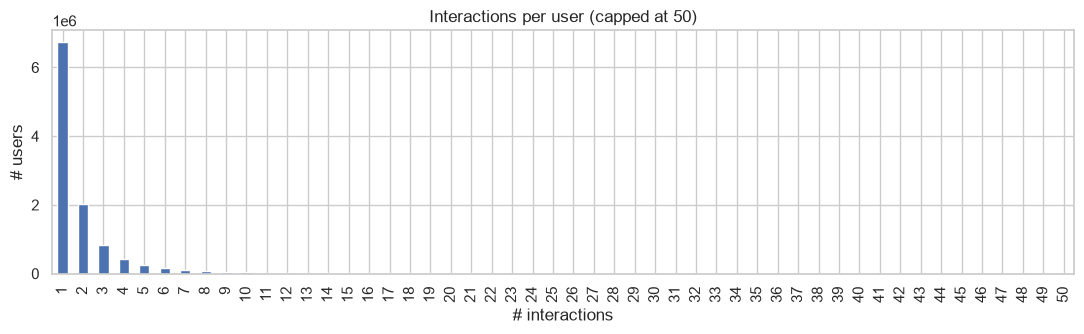

In [25]:
user_counts = interactions["user_id"].value_counts()
print(f"Users with exactly 1 interaction: {(user_counts == 1).mean():.2%}")
print(user_counts.describe(percentiles=[.5, .75, .9, .99]))

ax = user_counts.clip(upper=50).value_counts().sort_index().plot.bar(figsize=(11, 3.5))
ax.set(title="Interactions per user (capped at 50)", xlabel="# interactions", ylabel="# users")
plt.tight_layout(); plt.show()

### 2.4 How mainstream is each user?
**Why:** Popularity bias doesn't hit everyone equally. Users with niche taste suffer most when a model pushes popular items (Abdollahpouri et al., *The Unfairness of Popularity Bias*). Profiling users now lets you later compare model accuracy for niche vs. mainstream users.

            avg_item_pop  tail_ratio
group                               
mainstream   3468.556060    0.358893
diverse       322.047778    1.000000
niche         322.191926    1.000000


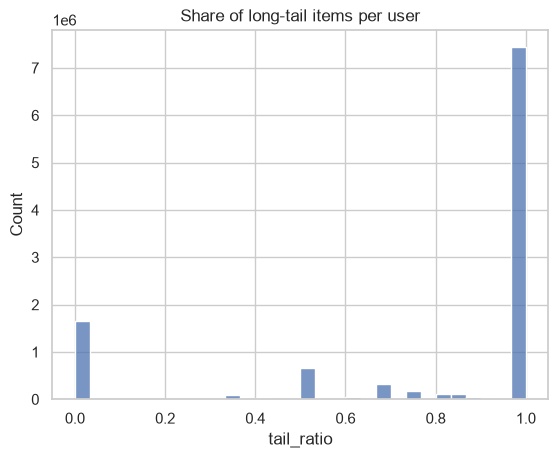

In [26]:
pop = interactions["parent_asin"].map(item_counts)
user_profile = (interactions.assign(item_pop=pop, is_tail=~interactions["parent_asin"].isin(HEAD_ITEMS))
                    .groupby("user_id")
                    .agg(avg_item_pop=("item_pop", "mean"), tail_ratio=("is_tail", "mean")))

user_profile["group"] = pd.qcut(user_profile["tail_ratio"].rank(method="first"), 3,
                                labels=["mainstream", "diverse", "niche"])
print(user_profile.groupby("group", observed=True)[["avg_item_pop", "tail_ratio"]].mean())
sns.histplot(user_profile["tail_ratio"], bins=30).set(title="Share of long-tail items per user")
plt.show()

### 2.5 Popularity vs. quality
**Why:** If popular items are also the best-rated, recommending them is partly justified. If there's little correlation, popularity bias is pushing items that are merely *visible*, which strengthens your motivation.

Spearman(popularity, mean rating) = -0.164 (p=0)


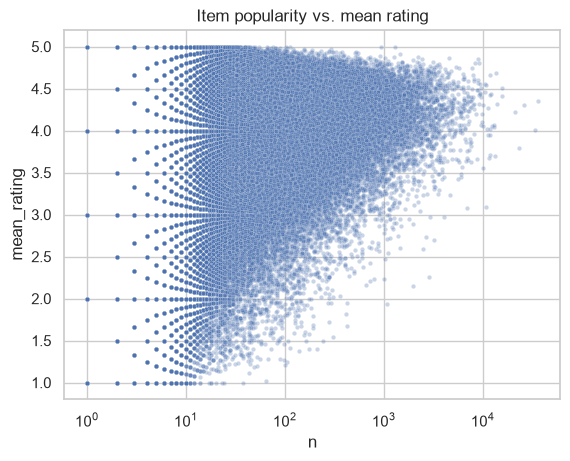

In [27]:
item_stats = interactions.groupby("parent_asin")["rating"].agg(n="count", mean_rating="mean")
rho, p = spearmanr(item_stats["n"], item_stats["mean_rating"])
print(f"Spearman(popularity, mean rating) = {rho:.3f} (p={p:.2g})")

ax = sns.scatterplot(data=item_stats, x="n", y="mean_rating", alpha=0.3, s=10)
ax.set(xscale="log", title="Item popularity vs. mean rating")
plt.show()

### 2.6 Time
**Why:** (a) Shows whether some years dominate the data. (b) Justifies a **temporal split**: random splits let models train on the future, which inflates accuracy and especially favours items that later became popular.

           interactions      gini
timestamp                        
2000                  2  0.000000
2001                  8  0.166667
2002                 19  0.092879
2003                 66  0.379679
2004                180  0.341742
2005                663  0.373054
2006               1095  0.393422
2007               3998  0.425439
2008               6233  0.404875
2009              12255  0.425223
2010              29516  0.477593
2011              66062  0.544421
2012             144501  0.592015
2013             456634  0.690673
2014             749116  0.730783
2015            1325316  0.764626
2016            1567675  0.768424
2017            1604570  0.768551
2018            1779509  0.765979
2019            2450551  0.784817
2020            3364834  0.801104
2021            3500456  0.791516
2022            3261789  0.786866
2023            1460321  0.737227


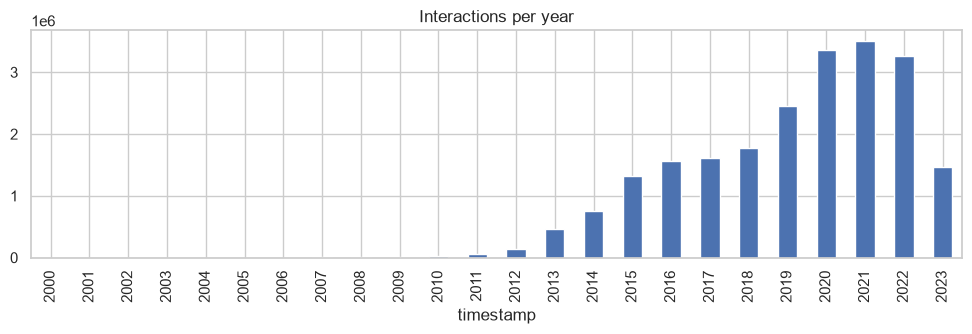

In [28]:
yearly = interactions.groupby(interactions["timestamp"].dt.year).agg(
    interactions=("user_id", "size"),
    gini=("parent_asin", lambda s: gini(s.value_counts())))
print(yearly)
yearly["interactions"].plot.bar(figsize=(10, 3.5), title="Interactions per year")
plt.tight_layout(); plt.show()

### 2.7 Store concentration (ties to your motivation)
**Why:** Your proposal cites the claim that ~2% of sellers drive >50% of revenue. You can check the review-level equivalent in your own data, which is a stronger motivation statement than an external blog.

In [29]:
m = interactions.merge(meta[["parent_asin", "store", "price", "main_category"]], on="parent_asin", how="left")
store_counts = m["store"].dropna().value_counts()
top = max(1, int(len(store_counts) * 0.02))
print(f"Top 2% of stores ({top:,}) account for {store_counts.iloc[:top].sum()/store_counts.sum():.2%} of reviews")
print(f"Store Gini: {gini(store_counts):.3f} | reviews with no store: {m['store'].isna().mean():.2%}")

Top 2% of stores (2,395) account for 68.86% of reviews
Store Gini: 0.929 | reviews with no store: 5.70%


### 2.8 Price vs. popularity
**Why:** If popular items cluster at low prices, a niche-boosting model may also shift recommendations toward pricier items. Useful context for discussing trade-offs.

In [30]:
pp = item_stats.join(meta.set_index("parent_asin")["price"]).dropna(subset=["price"])
print(f"Items with a price: {len(pp)/len(item_stats):.2%}")
if len(pp) > 10:
    pp["price_bin"] = pd.qcut(pp["price"], 5, duplicates="drop")
    print(pp.groupby("price_bin", observed=True)["n"].agg(["median", "mean", "count"]))

Items with a price: 37.28%
                 median       mean  count
price_bin                                
(-0.001, 8.99]      4.0  40.474031  80366
(8.99, 12.99]       4.0  41.407214  66648
(12.99, 19.99]      5.0  47.793960  75961
(19.99, 33.8]       5.0  47.953321  65511
(33.8, 9999.99]     4.0  36.236302  72111


## 3. Train/test split & save
Temporal leave-last-out: each user's **most recent** interaction goes to test. Test items never seen in training are dropped, because CF/MF can't score unseen items. Report how many you drop.

In [31]:
interactions = interactions.sort_values(["user_id", "timestamp"])
test = interactions.groupby("user_id").tail(1)
train = interactions.drop(test.index)
test = test[test["user_id"].isin(train["user_id"]) & test["parent_asin"].isin(train["parent_asin"])]
print(f"train: {len(train):,} | test: {len(test):,} users")
print(f"test kept: {len(test):,}")

out = DATA_DIR / "processed"; out.mkdir(parents=True, exist_ok=True)
train.to_csv(out / f"{CATEGORY}_train.csv", index=False)
test.to_csv(out / f"{CATEGORY}_test.csv", index=False)
pd.Series(sorted(HEAD_ITEMS), name="parent_asin").to_csv(out / f"{CATEGORY}_head_items.csv", index=False)

train: 10,970,405 | test: 3,962,760 users
test kept: 3,962,760


## 4. Cross-category comparison
Run the profile below on each category so all three appear in one table. Different Gini / head shares across categories give you a hypothesis to test: *does bias amplification grow with how concentrated the data already is?*

`max_rows` lets you sample the very large categories (Clothing, Shoes & Jewelry has tens of millions of reviews) on a laptop. Use the same sampling rule for every category.

In [ ]:
def profile_category(cat, max_rows=None, k=5):
    r = pd.read_parquet(
        DATA_DIR / f"{cat}_full.parquet",
        columns=["user_id", "parent_asin", "rating", "timestamp", "verified_purchase"]
    )
    if ONLY_VERIFIED:
        r = r[r["verified_purchase"] == True]
    r = r.drop_duplicates(["user_id", "parent_asin"], keep="last")
    row = summarize(r, cat)
    counts, head = head_tail(r)
    row["gini_raw"] = gini(r["parent_asin"].value_counts())
    row["gini_core"] = gini(counts)
    row["head_item_share"] = len(head) / len(counts) if len(counts) else np.nan
    row["mean_rating"] = r["rating"].mean()
    return row

CATEGORIES = ["Beauty_and_Personal_Care"]   # add the others once downloaded
comparison = pd.concat([profile_category(c) for c in CATEGORIES], axis=1).T
comparison